# Creative Semantic Retrieval: *The Midnight Museum*
### Retrieving artworks, poems, photographs, sound clips and film scenes for abstract, emotional queries

**Part A: Mini Project, Question 1 (Creative Semantic Retrieval)**
**Student:** _&lt;name / ID&gt;_

This notebook builds and analyses an embedding-based retrieval system for the *"Alien Artifact Matcher"* direction suggested in the brief. A visitor describes a feeling or an abstract idea (*"the loneliness of an empty train station at 3 AM"*), and the system returns the five most semantically similar works from a 125-item museum collection.

**Pipeline** (every step is implemented in this notebook):

1. **Embed** every item (modality + title + description) and the query into vectors.
2. **Compare** the query vector with every item vector using cosine similarity.
3. **Rank** the items by similarity.
4. **Return** the top 5.

To understand *where* embeddings succeed and fail, rather than only showing that they work, the notebook also:

* compares four representations: a lexical **TF-IDF** baseline, raw **BERT** (a language model *not* trained for similarity), the small **MiniLM** sentence encoder, and the larger **GTE-large** encoder, which performed best and is used as the **final system**;
* evaluates **14 queries** designed to probe different semantic phenomena: literal, abstract, metaphor, negation, opposite sentiment on the same topic, paraphrase, a modality constraint, a one-word ambiguous query and a cross-lingual (Arabic) query;
* measures, with relevance labels fixed *before* running any model, how often the system retrieves **decoys**: items that share the query's topic or words but not its meaning.

**Key findings** (details in Sections 7–9):

* **GTE-large reaches nDCG@5 = 0.74 and P@5 = 0.69**, against 0.48 / 0.45 for MiniLM, 0.18 / 0.17 for TF-IDF and 0.06 / 0.08 for random ranking.
* Embeddings excel when the intended feeling is **stated through concepts the items depict**: awe, anger at injustice and nostalgia score nDCG@5 = 1.00 with no shared keywords.
* They fail when meaning must be **inferred**: metaphor (0.48), humour (0.52) and a query in Arabic (0.00).
* **Negation, antonyms and word order barely register**: *"a night that is lonely"* vs *"… not lonely"* has cosine similarity 0.95–0.97, higher than a genuine paraphrase pair.
* The embedding space is organised by **form more than feeling**: an item's nearest neighbour shares its modality 92% of the time, but its emotional theme only 17%.

## 0. Datasets, models and external resources used

| Resource | What it is | Role in this project |
|---|---|---|
| **Midnight Museum collection** (`data/artifacts.json`) | **Self-created dataset** of 125 short, original descriptions of artworks: 23 poems, 18 paintings, 28 photographs, 21 sound clips, 16 sculptures/installations, 19 film scenes. Each item has a *hidden* theme label (15 themes) used only for analysis, never embedded. | Retrieval corpus |
| **Query set + relevance judgements** (`data/queries.json`) | **Self-created**: 14 queries with graded relevance labels (2 = matches the intended meaning, 1 = partial match) and a list of *decoys* per query. All labels were written before any model was run. | Evaluation |
| [`sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) | Pretrained sentence-embedding model (6 layers, 22.7M parameters, 384-d), contrastively fine-tuned on ~1B sentence pairs. Apache-2.0. | Lightweight retriever (15× fewer parameters) |
| [`thenlper/gte-large`](https://huggingface.co/thenlper/gte-large) | Pretrained general text-embedding model (24 layers, 335M parameters, 1024-d), contrastively trained on large-scale text pairs. MIT licence. | **Final retriever** (best in the evaluation) |
| [`bert-base-uncased`](https://huggingface.co/bert-base-uncased) | Pretrained masked language model (110M parameters, 768-d), **not** trained for sentence similarity. Apache-2.0. | Ablation: does sentence-level training matter? |
| TF-IDF (`scikit-learn`) | Sparse bag-of-words weighting | Lexical (non-semantic) baseline |
| Libraries | PyTorch, Hugging Face `transformers`, scikit-learn, NumPy, pandas, matplotlib | Model inference, t-SNE, metrics, plotting |

No model is trained or fine-tuned. The pretrained models are used *as is*, and the embedding, pooling, similarity, ranking and evaluation logic is written out below rather than hidden behind a retrieval library.

## 1. Setup

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Markdown, display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score
from transformers import AutoModel, AutoTokenizer
from transformers.utils import logging as hf_logging

warnings.filterwarnings("ignore")
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
torch.set_grad_enabled(False)  # inference only
torch.manual_seed(0)
np.random.seed(0)

DATA_DIR = Path("data")
TOP_K = 5
PRIMARY = "GTE-large"  # final system (chosen after the comparison in Section 7)

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 220)

# Plot styling: colour-blind-safe categorical slots, one-hue sequential ramp, recessive axes.
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#898781"
INK, INK2, GRIDC, AXISC, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXISC, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRIDC, "grid.linewidth": 0.8, "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "figure.dpi": 110, "legend.frameon": False,
})

DIVERGING = LinearSegmentedColormap.from_list(
    "diverging", ["#b3302f", "#e88c8b", "#f0efec", "#86b6ef", "#1c5cab"])  # red <- neutral grey -> blue


def draw_heatmap(ax, values, xlabels, ylabels, cmap, norm, fmt="{:.2f}", fontsize=9):
    """Annotated heatmap with a 2px surface gap between cells; text colour adapts to the cell colour."""
    n_rows, n_cols = values.shape
    mesh = ax.pcolormesh(values, cmap=cmap, norm=norm, edgecolors=SURFACE, linewidth=2)
    for (r, c), v in np.ndenumerate(values):
        red, green, blue, _ = cmap(norm(v))
        dark_cell = 0.2126 * red + 0.7152 * green + 0.0722 * blue < 0.5
        ax.text(c + 0.5, r + 0.5, fmt.format(v), ha="center", va="center", fontsize=fontsize,
                color="white" if dark_cell else INK)
    ax.set_xticks(np.arange(n_cols) + 0.5, xlabels)
    ax.set_yticks(np.arange(n_rows) + 0.5, ylabels)
    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)  # first row at the top
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    return mesh


print(f"torch {torch.__version__} | transformers ready | CPU inference")

torch 2.14.0+cpu | transformers ready | CPU inference


## 2. The dataset: a self-created museum collection

Every item is a short, original description of a work in one of six modalities. The collection covers 15 emotional themes (loneliness at night, nostalgia, joy, grief, hope, urban anxiety, serene nature, love, cosmic awe, anger at injustice, time and decay, homecoming, fear, humour, wanderlust).

It is **deliberately adversarial**. Several items share surface words with a query but carry a different meaning. For example, the collection contains seven train or station scenes, but only two of them are lonely. The others are a joyful Eid train, a rush-hour crush, a soldier's reunion on a platform, a sleeper compartment where strangers become friends and a jungle-covered ruin. Rain appears at a funeral, on a cosy tin roof, during an eviction and in a joyful monsoon dance. These traps are what let us test whether the system retrieves *meaning* or just *topic*.

The text that gets embedded for each item is `"<Modality>: <Title>. <Description>"`.

In [2]:
artifacts = json.loads((DATA_DIR / "artifacts.json").read_text(encoding="utf-8"))
queries = json.loads((DATA_DIR / "queries.json").read_text(encoding="utf-8"))

items = pd.DataFrame(artifacts).set_index("id")


def item_to_text(item):
    """Text embedded for an item: modality, title and description.
    The 'theme' column is a hidden label used only for analysis; it is never embedded."""
    return f"{item['type'].capitalize()}: {item['title']}. {item['description']}"


items["text"] = items.apply(item_to_text, axis=1)
item_ids = items.index.to_numpy()

print(f"{len(items)} items | {items['type'].nunique()} modalities | {items['theme'].nunique()} hidden themes | "
      f"mean description length {items['description'].str.split().str.len().mean():.0f} words\n")
display(pd.crosstab(items["theme"], items["type"], margins=True, margins_name="total"))

125 items | 6 modalities | 15 hidden themes | mean description length 28 words



type,film scene,painting,photograph,poem,sculpture,sound clip,total
theme,,,,,,,
anger_protest,1,1,2,2,1,1,8
cosmic_awe,1,1,2,2,1,1,8
fear_dread,2,1,1,1,1,2,8
grief_loss,1,2,1,2,1,3,10
homecoming_belonging,2,1,2,1,1,1,8
hope_renewal,1,1,2,2,1,1,8
joy_celebration,3,1,3,1,1,1,10
love_romance,1,2,1,2,1,1,8
nature_serenity,1,1,2,1,1,2,8


In [3]:
print("Example item texts (exactly what the models see):\n")
for i in [1, 17, 32, 67, 107]:
    print(f"[{i}] {items.loc[i, 'text']}\n")

Example item texts (exactly what the models see):

[1] Photograph: Platform 4, 3:12 AM. A single fluorescent tube hums above rows of empty benches. The departure board has gone blank for the night, and a paper cup drifts along the tiles in the draft. No one is waiting for anything.

[17] Film scene: The Eid Express. A crowded night train packed with families travelling home for the holidays. Children run between the seats, strangers share sweets and tea, and the whole carriage bursts into laughter when a baby sneezes.

[32] Poem: The House After. We turned off the lights one by one / the night after the funeral, / and the house went dark / the way a face does / when it finally stops pretending.

[67] Poem: Speck. From far enough away / every war we ever fought / fits on a speck of dust / hanging in a sunbeam. / I find this / oddly comforting.

[107] Poem: Complaint from a Sock. I was one of a pair. / Then came the washing machine. / I have questions, / and I have lawyers.



### The evaluation queries

Each query targets a different kind of semantic challenge. For every query, the relevance labels in `queries.json` list which items match the **intended meaning** (grade 2), which match only partially (grade 1, e.g. the right feeling but the wrong setting) and which are **decoys**: items on the same topic or sharing words with the query, but with a different meaning. Unlisted items count as not relevant. Q11 (`"blue"`) is intentionally ambiguous and is analysed qualitatively, not scored.

In [4]:
SHORT = {q["qid"]: s for q, s in zip(queries, [
    "mood + setting", "nostalgia", "awe", "anger at injustice", "literal / easy", "modality + grief",
    "negation", "metaphor", "opposite sentiment", "paraphrase", "ambiguous word", "humour",
    "English control", "Arabic"])}

display(pd.DataFrame([{
    "qid": q["qid"], "tests": q["category"], "query": q["query"], "intended meaning": q["intent"],
    "grade 2": sum(v == 2 for v in q["relevant"].values()),
    "grade 1": sum(v == 1 for v in q["relevant"].values()),
    "decoys": len(q["decoys"]),
} for q in queries]).set_index("qid"))

,tests,query,intended meaning,grade 2,grade 1,decoys
qid,,,,,,
Q1,Mood + concrete setting (assignment example),the loneliness of an empty train station at 3 AM,solitary emptiness in a transit space late at night,4,6,6
Q2,Abstract emotion (nostalgia),the bittersweet feeling of a childhood summer that will never come back,nostalgic longing for lost childhood summers,3,8,1
Q3,Abstract emotion (awe),feeling tiny under the vastness of the universe,cosmic scale that makes a human feel small,7,1,1
Q4,Emotion + target (anger at injustice),burning rage against injustice,"anger directed at an unjust situation (protest, exploitation, eviction)",7,0,3
Q5,Easy / literal control query,"a calm, peaceful morning in nature",tranquil natural scene at dawn or early morning,5,5,2
Q6,Modality constraint + emotion,a sound clip that captures grief,an audio item (not a poem or picture) about mourning,3,7,0
Q7,Negation,"a night that is not lonely at all, full of people and celebration","crowded, festive night-time scenes; explicitly NOT lonely ones",5,5,9
Q8,Metaphor / figurative language,a heart like a house with all the lights switched off,"emotional darkness: grief, emptiness, depression (not literal houses or lights)",2,8,3
Q9,"Same topic, opposite sentiment",rain that makes you want to dance,"joyful, exhilarating rain (not sad or merely calm rain)",2,3,5


## 3. Step 1: Converting text into embeddings

Two kinds of encoders share the same interface (`fit` + `encode`):

**(a) TF-IDF, the lexical baseline.** Each text becomes a sparse vector with one dimension per vocabulary word, weighted by how frequent the word is in the text and how rare it is across the collection. Two texts are similar only if they share *exact* words: `train` ≠ `trains`, `sad` ≠ `grief`.

**(b) Transformer sentence embeddings.** A pretrained transformer turns each (sub)word token into a *contextual* vector. We turn these into one vector per text with **mean pooling**: we average the token vectors, using the attention mask so that padding tokens are ignored. This is exactly how MiniLM and GTE-large are meant to be used: both specify mean pooling in their model configuration. Because these models were fine-tuned with a contrastive objective (pull matching sentence pairs together, push random pairs apart), texts with similar *meaning* end up close in the vector space even when they share no words.

Raw `bert-base-uncased` is embedded in the same way as an ablation. It has the same kind of architecture but was never trained to make sentence vectors comparable.

In [5]:
def load_pretrained(cls, model_id):
    """Load from the local Hugging Face cache if the model is already there; download it otherwise."""
    try:
        return cls.from_pretrained(model_id, local_files_only=True)
    except Exception:
        return cls.from_pretrained(model_id)


class TfidfEncoder:
    """Sparse lexical vectors: one dimension per vocabulary word, TF-IDF weighted."""

    def fit(self, corpus):
        self.vectorizer = TfidfVectorizer(stop_words="english", sublinear_tf=True).fit(corpus)
        return self

    def encode(self, texts):
        return self.vectorizer.transform(texts).toarray().astype(np.float32)


class TransformerEncoder:
    """Dense sentence embeddings from a pretrained transformer.

    text -> subword tokens -> transformer -> one contextual vector per token
         -> mean pooling over real (non-padding) tokens -> one vector per text
    """

    def __init__(self, model_id, max_length=256, batch_size=16):
        self.model_id, self.max_length, self.batch_size = model_id, max_length, batch_size
        self.tokenizer = load_pretrained(AutoTokenizer, model_id)
        self.model = load_pretrained(AutoModel, model_id).float().eval()  # float32 on CPU

    def fit(self, corpus):
        return self  # pretrained: nothing to fit

    def encode(self, texts):
        vectors = []
        for start in range(0, len(texts), self.batch_size):
            batch = self.tokenizer(texts[start:start + self.batch_size], padding=True, truncation=True,
                                   max_length=self.max_length, return_tensors="pt")
            token_vectors = self.model(**batch).last_hidden_state            # (batch, tokens, dim)
            mask = batch["attention_mask"].unsqueeze(-1).float()             # 1 = real token, 0 = padding
            mean_pooled = (token_vectors * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)
            vectors.append(mean_pooled.numpy())
        return np.vstack(vectors).astype(np.float32)

## 4. Step 2: Cosine similarity

Cosine similarity compares the **direction** of two vectors and ignores their length:

$$\cos(\mathbf{q}, \mathbf{d}) = \frac{\mathbf{q}\cdot\mathbf{d}}{\lVert\mathbf{q}\rVert\,\lVert\mathbf{d}\rVert} \in [-1, 1]$$

If we L2-normalise every vector first, cosine similarity becomes a plain dot product, so one matrix multiplication scores every (query, item) pair at once.

In [6]:
def l2_normalize(matrix):
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.maximum(norms, 1e-12)  # guard: an all-zero vector stays all-zero


def cosine_similarity_matrix(query_vectors, item_vectors):
    """Cosine similarity for every (query, item) pair. Shape: (n_queries, n_items)."""
    return l2_normalize(query_vectors) @ l2_normalize(item_vectors).T


# Sanity check against a direct, loop-based implementation of the formula.
a, b = np.random.rand(3, 8), np.random.rand(4, 8)
direct = np.array([[x @ y / (np.linalg.norm(x) * np.linalg.norm(y)) for y in b] for x in a])
assert np.allclose(cosine_similarity_matrix(a, b), direct)
print("cosine_similarity_matrix matches the formula ✓")

cosine_similarity_matrix matches the formula ✓


## 5. Steps 3–4: Ranking and returning the top 5

The search engine embeds the collection **once** (the "index"). At query time it embeds only the query, scores it against all 125 item vectors, sorts the scores in descending order and returns the top *k*.

In [7]:
class SemanticSearch:
    def __init__(self, encoder, items):
        self.encoder, self.items = encoder, items
        texts = items["text"].tolist()
        start = time.perf_counter()
        self.item_vectors = encoder.fit(texts).encode(texts)                   # (n_items, dim)
        self.index_seconds = time.perf_counter() - start

    def similarities(self, query):
        query_vector = self.encoder.encode([query])                            # (1, dim)
        return cosine_similarity_matrix(query_vector, self.item_vectors)[0]    # (n_items,)

    def ranking(self, query):
        """All item ids ordered from most to least similar, with their cosine scores."""
        scores = self.similarities(query)
        order = np.argsort(-scores, kind="stable")                              # descending similarity
        return self.items.index[order].to_numpy(), scores[order]

    def search(self, query, k=TOP_K):
        ids, scores = self.ranking(query)
        top = self.items.loc[ids[:k], ["type", "title"]].copy()
        top.insert(0, "rank", np.arange(1, k + 1))
        top["cosine"] = scores[:k].round(3)
        return top


ENCODERS = {
    "TF-IDF": lambda: TfidfEncoder(),
    "BERT": lambda: TransformerEncoder("bert-base-uncased"),
    "MiniLM": lambda: TransformerEncoder("sentence-transformers/all-MiniLM-L6-v2"),
    "GTE-large": lambda: TransformerEncoder("thenlper/gte-large"),
}
MODELS = list(ENCODERS)

engines = {name: SemanticSearch(make(), items) for name, make in ENCODERS.items()}

display(pd.DataFrame([{
    "model": name,
    "vector dimensions": e.item_vectors.shape[1],
    "non-zero dims per item (mean)": int((e.item_vectors != 0).sum(1).mean()),
    "time to index 125 items (s)": round(e.index_seconds, 2),
} for name, e in engines.items()]).set_index("model"))

,vector dimensions,non-zero dims per item (mean),time to index 125 items (s)
model,,,
TF-IDF,1241,16,0.01
BERT,768,768,6.74
MiniLM,384,384,0.97
GTE-large,1024,1024,22.60


A first look: the final system (GTE-large) answering the example query from the assignment brief.

In [8]:
engines[PRIMARY].search("the loneliness of an empty train station at 3 AM")

,rank,type,title,cosine
id,,,,
1,1,photograph,"Platform 4, 3:12 AM",0.905
81,2,photograph,Abandoned Station,0.871
117,3,film scene,Sleeper Compartment,0.853
48,4,photograph,Neon Insomnia,0.853
2,5,sound clip,Last Announcement,0.852


## 6. Results for every query, with manual relevance assessment

For each query, the table shows the top 5 from the final system (**GTE-large**), the small **MiniLM** model and the lexical **TF-IDF** baseline, side by side with their cosine scores. Cosine scores are only comparable *within* one model: GTE-large puts almost every pair between 0.7 and 0.9, while MiniLM uses a much wider range (see Section 8.2). The *judgement* column is the manual relevance assessment taken from the labels fixed in advance:

* `✓ relevant`: matches the intended meaning
* `~ partial`: right feeling but a missing constraint (e.g. lonely, but not a station), or vice versa
* `✗ DECOY`: shares the topic or words but **not** the intended meaning
* `✗`: not relevant

Raw BERT is left out of these tables to keep them readable. It is scored in Section 7.

In [9]:
def judge(q, item_id):
    """Manual relevance judgement for one retrieved item (labels fixed in queries.json before running)."""
    if not q["relevant"]:
        return "(unscored)"
    grade = q["relevant"].get(str(item_id), 0)
    if grade == 2:
        return "✓ relevant"
    if grade == 1:
        return "~ partial"
    return "✗ DECOY" if item_id in q["decoys"] else "✗"


def show_results(q, models=("GTE-large", "MiniLM", "TF-IDF")):
    display(Markdown(f"#### {q['qid']} · {q['category']}\n"
                     f"**Query:** “{q['query']}”  \n*Intended meaning:* {q['intent']}"))
    columns = {}
    for m in models:
        ids, scores = engines[m].ranking(q["query"])
        columns[(m, "retrieved item")] = [f"[{i}] {items.loc[i, 'title']} ({items.loc[i, 'type']})"
                                          for i in ids[:TOP_K]]
        columns[(m, "cos")] = scores[:TOP_K].round(3)
        columns[(m, "judgement")] = [judge(q, i) for i in ids[:TOP_K]]
    display(pd.DataFrame(columns, index=pd.RangeIndex(1, TOP_K + 1, name="rank")))


for q in queries:
    show_results(q)

#### Q1 · Mood + concrete setting (assignment example)
**Query:** “the loneliness of an empty train station at 3 AM”  
*Intended meaning:* solitary emptiness in a transit space late at night

GTE-large                                                          MiniLM                                                         TF-IDF                   
                              retrieved item    cos   judgement                               retrieved item    cos  judgement                               retrieved item    cos   judgement
rank                                                                                                                                                                                          
1       [1] Platform 4, 3:12 AM (photograph)  0.905  ✓ relevant          [41] Rush Hour, Line 2 (sound clip)  0.507    ✗ DECOY  [90] Arrivals, Central Station (photograph)  0.306     ✗ DECOY
2        [81] Abandoned Station (photograph)  0.871   ~ partial          [81] Abandoned Station (photograph)  0.491  ~ partial          [81] Abandoned Station (photograph)  0.272   ~ partial
3     [117] Sleeper Compartment (film scene)  0.853     ✗ DECOY              [48] Neon Insomnia (photograph)  0.409  ~ partial           [2] Last Announcement (sound clip)  0.134  ✓ relevant
4            [48] Neon Insomnia (photograph)  0.853   ~ partial  [90] Arrivals, Central Station (photograph)  0.396    ✗ DECOY       [117] Sleeper Compartment (film scene)  0.129     ✗ DECOY
5         [2] Last Announcement (sound clip)  0.852  ✓ relevant                      [8] Ghost Signal (poem)  0.396  ~ partial            [17] The Eid Express (film scene)  0.126     ✗ DECOY

#### Q2 · Abstract emotion (nostalgia)
**Query:** “the bittersweet feeling of a childhood summer that will never come back”  
*Intended meaning:* nostalgic longing for lost childhood summers

GTE-large                                                       MiniLM                                                       TF-IDF                   
                                retrieved item    cos   judgement                            retrieved item    cos   judgement                            retrieved item    cos   judgement
rank                                                                                                                                                                                       
1       [9] Polaroid, August 1998 (photograph)  0.827  ✓ relevant           [22] First Monsoon (photograph)  0.381     ✗ DECOY             [122] Glow Stars (photograph)  0.191   ~ partial
2     [12] Last Day of the Holidays (painting)  0.823  ✓ relevant  [12] Last Day of the Holidays (painting)  0.333  ✓ relevant  [12] Last Day of the Holidays (painting)  0.142  ✓ relevant
3               [30] Ashes at Sea (film scene)  0.803           ✗        [86] Time-Lapse House (film scene)  0.311           ✗       [33] Green Through Ash (photograph)  0.136           ✗
4           [86] Time-Lapse House (film scene)  0.802           ✗               [99] The Visitor (painting)  0.310           ✗    [9] Polaroid, August 1998 (photograph)  0.127  ✓ relevant
5          [89] The Long Way Home (film scene)  0.796           ✗    [9] Polaroid, August 1998 (photograph)  0.304  ✓ relevant      [1] Platform 4, 3:12 AM (photograph)  0.000           ✗

#### Q3 · Abstract emotion (awe)
**Query:** “feeling tiny under the vastness of the universe”  
*Intended meaning:* cosmic scale that makes a human feel small

GTE-large                                                          MiniLM                                                          TF-IDF                   
                                   retrieved item    cos   judgement                               retrieved item    cos   judgement                               retrieved item    cos   judgement
rank                                                                                                                                                                                                
1                    [71] Deep Field (photograph)  0.839  ✓ relevant                 [71] Deep Field (photograph)  0.402  ✓ relevant         [110] Dog in Sunglasses (photograph)  0.228           ✗
2     [65] Milky Way Over the Desert (photograph)  0.832  ✓ relevant  [65] Milky Way Over the Desert (photograph)  0.361  ✓ relevant   [20] Fireworks Over the Harbour (painting)  0.218           ✗
3                   [72] Stargazing Lesson (poem)  0.831  ✓ relevant               [66] Plasma Waves (sound clip)  0.300   ~ partial  [65] Milky Way Over the Desert (photograph)  0.200  ✓ relevant
4                    [70] Scale Model (sculpture)  0.816  ✓ relevant                [72] Stargazing Lesson (poem)  0.298  ✓ relevant         [1] Platform 4, 3:12 AM (photograph)  0.000           ✗
5                     [69] Earthrise (film scene)  0.807  ✓ relevant                 [113] Departure (photograph)  0.291           ✗           [2] Last Announcement (sound clip)  0.000           ✗

... (18 outputs left out)

#### Q13 · Cross-lingual control (English)
**Query:** “nostalgia for the days of childhood”  
*Intended meaning:* nostalgic memories of childhood

GTE-large                                                       MiniLM                                                   TF-IDF                   
                                 retrieved item    cos   judgement                            retrieved item    cos   judgement                        retrieved item    cos   judgement
rank                                                                                                                                                                                    
1             [11] Grandmother's Kitchen (poem)  0.807  ✓ relevant         [13] The Old Cartoon (film scene)  0.361  ✓ relevant         [122] Glow Stars (photograph)  0.253  ✓ relevant
2             [13] The Old Cartoon (film scene)  0.802  ✓ relevant  [12] Last Day of the Holidays (painting)  0.331  ✓ relevant  [1] Platform 4, 3:12 AM (photograph)  0.000           ✗
3                 [122] Glow Stars (photograph)  0.795  ✓ relevant            [95] Sunday Lunch (photograph)  0.326           ✗    [2] Last Announcement (sound clip)  0.000           ✗
4        [9] Polaroid, August 1998 (photograph)  0.791  ✓ relevant        [86] Time-Lapse House (film scene)  0.322           ✗                [3] Gate 31 (painting)  0.000           ✗
5     [10] Ice-Cream Van, Far Away (sound clip)  0.789  ✓ relevant                        [84] Mirror (poem)  0.318           ✗                  [4] Night Bus (poem)  0.000           ✗

#### Q14 · Cross-lingual (Arabic, same meaning as Q13)
**Query:** “الحنين إلى أيام الطفولة”  
*Intended meaning:* same as Q13, asked in Arabic

GTE-large                                              MiniLM                                                 TF-IDF               
                         retrieved item    cos judgement                     retrieved item    cos judgement                        retrieved item  cos judgement
rank                                                                                                                                                             
1         [56] Desert Dawn (photograph)  0.791         ✗      [56] Desert Dawn (photograph)  0.245         ✗  [1] Platform 4, 3:12 AM (photograph)  0.0         ✗
2       [92] Mother Tongue (sound clip)  0.787         ✗  [116] Caravan at Night (painting)  0.209         ✗    [2] Last Announcement (sound clip)  0.0         ✗
3     [17] The Eid Express (film scene)  0.782         ✗  [5] Laundromat, 2 AM (photograph)  0.205         ✗                [3] Gate 31 (painting)  0.0         ✗
4     [116] Caravan at Night (painting)  0.781         ✗             [3] Gate 31 (painting)  0.194         ✗                  [4] Night Bus (poem)  0.0         ✗
5               [24] Goal! (film scene)  0.780         ✗                   [115] Map (poem)  0.192         ✗     [5] Laundromat, 2 AM (photograph)  0.0         ✗

## 7. Quantitative evaluation

Using the fixed relevance labels, each ranking is scored with standard information-retrieval metrics:

| Metric | Meaning |
|---|---|
| **P@5** | fraction of the top 5 that is relevant (grade ≥ 1) |
| **nDCG@5** | ranking quality that rewards grade-2 items more than grade-1 items and rewards placing them higher; 1.0 = ideal ordering |
| **MRR** | 1 / rank of the first fully relevant (grade 2) item, averaged over queries |
| **AUC** | probability that a random relevant item scores above a random irrelevant one, over the *whole* ranking (0.5 = chance) |
| **Decoys@5** | number of decoy items in the top 5; this directly measures *"related to the topic but not the intended meaning"* |

A **random ranker** (averaged over 300 shuffles) gives the chance level.

In [10]:
def dcg(grades):
    return sum((2 ** g - 1) / np.log2(rank + 2) for rank, g in enumerate(grades))


def evaluate_ranking(ids, scores, q, k=TOP_K):
    grades = [q["relevant"].get(str(i), 0) for i in ids]
    ideal = sorted(q["relevant"].values(), reverse=True)
    is_relevant = np.array([g > 0 for g in grades])
    first_full = next((rank for rank, g in enumerate(grades, 1) if g == 2), None)
    return {
        "P@5": is_relevant[:k].mean(),
        "nDCG@5": dcg(grades[:k]) / dcg(ideal[:k]),
        "MRR": 1 / first_full if first_full else 0.0,
        "AUC": roc_auc_score(is_relevant, scores),
        "Decoys@5": sum(i in q["decoys"] for i in ids[:k]),
    }


scored_queries = [q for q in queries if q["relevant"]]
records = [{"model": name, "qid": q["qid"], **evaluate_ranking(*engine.ranking(q["query"]), q)}
           for name, engine in engines.items() for q in scored_queries]

rng = np.random.default_rng(0)
for q in scored_queries:
    trials = []
    for _ in range(300):
        random_scores = rng.random(len(item_ids))
        order = np.argsort(-random_scores)
        trials.append(evaluate_ranking(item_ids[order], random_scores[order], q))
    records.append({"model": "Random", "qid": q["qid"], **pd.DataFrame(trials).mean().to_dict()})

metrics = pd.DataFrame(records)
MODEL_ORDER = ["Random"] + MODELS
summary = metrics.groupby("model")[["P@5", "nDCG@5", "MRR", "AUC", "Decoys@5"]].mean().loc[MODEL_ORDER]
summary["Decoys@5 (total)"] = metrics.groupby("model")["Decoys@5"].sum().loc[MODEL_ORDER]
summary = summary.drop(columns="Decoys@5")
print(f"Mean over {len(scored_queries)} scored queries (Q11 'blue' excluded):")
display(summary.round(3))

Mean over 13 scored queries (Q11 'blue' excluded):


,P@5,nDCG@5,MRR,AUC,Decoys@5 (total)
model,,,,,
Random,0.075,0.057,0.137,0.498,1.293
TF-IDF,0.169,0.183,0.344,0.557,10.000
BERT,0.323,0.335,0.523,0.721,4.000
MiniLM,0.446,0.481,0.733,0.777,9.000
GTE-large,0.692,0.743,0.926,0.866,7.000


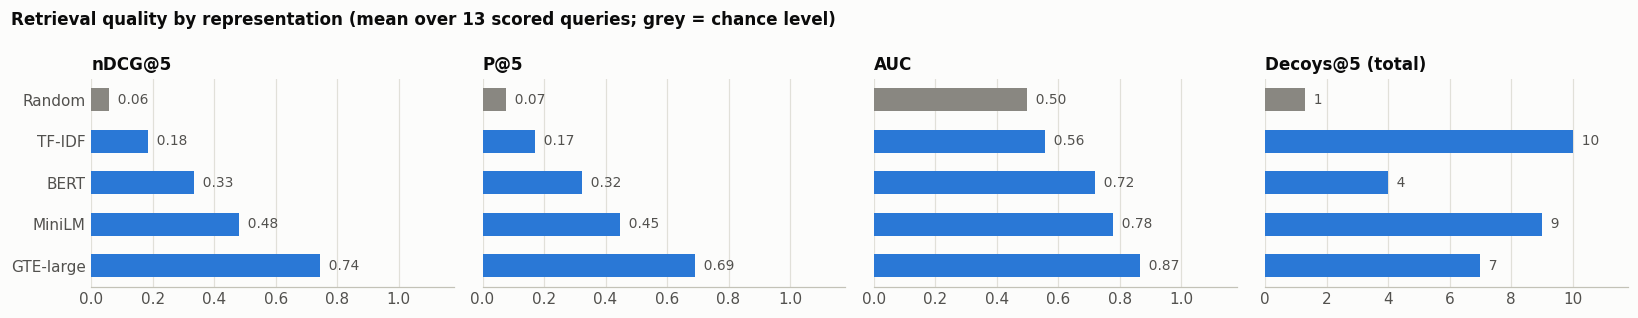

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(15, 2.9), sharey=True)
panels = [("nDCG@5", (0, 1)), ("P@5", (0, 1)), ("AUC", (0, 1)), ("Decoys@5 (total)", None)]
y = np.arange(len(MODEL_ORDER))
for ax, (col, xlim) in zip(axes, panels):
    values = summary[col].to_numpy()
    colors = [GREY if m == "Random" else BLUE for m in MODEL_ORDER]
    ax.barh(y, values, height=0.55, color=colors)
    for yi, v in zip(y, values):
        ax.text(v, yi, f"  {v:.2f}" if col != "Decoys@5 (total)" else f"  {v:.0f}",
                va="center", fontsize=9, color=INK2)
    ax.set_title(col, loc="left")
    ax.set_xlim(0, (xlim[1] if xlim else values.max()) * 1.18)
    ax.xaxis.grid(True)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.spines["left"].set_visible(False)
axes[0].set_yticks(y, MODEL_ORDER)
axes[0].invert_yaxis()
fig.suptitle("Retrieval quality by representation (mean over 13 scored queries; grey = chance level)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

### Per-query breakdown

nDCG@5 for each query and model. This shows *which kinds of queries* each representation handles well.

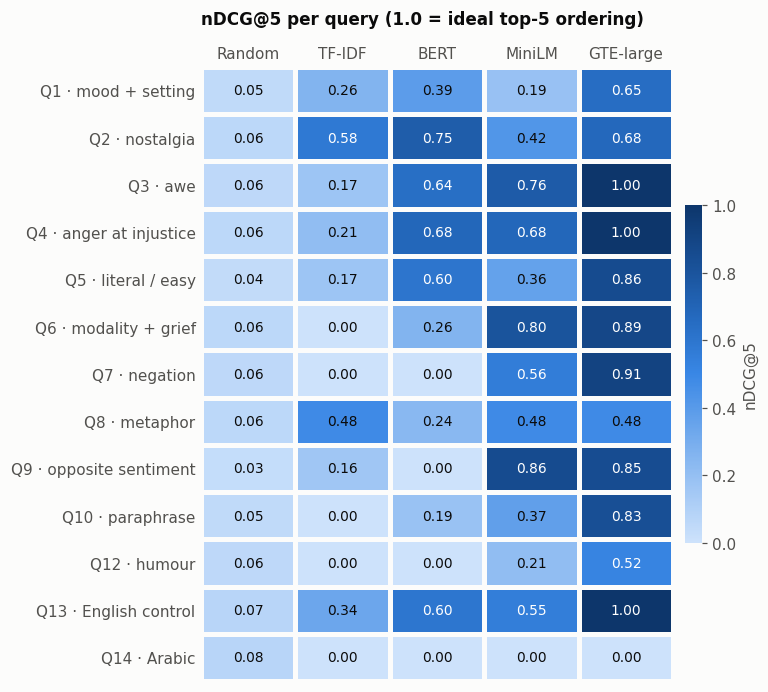

tests       P@5                  nDCG@5                Decoys@5              
model                     GTE-large MiniLM TF-IDF GTE-large MiniLM TF-IDF GTE-large MiniLM TF-IDF
qid                                                                                              
Q1         mood + setting       0.8    0.6    0.4      0.65   0.19   0.26       1.0    2.0    3.0
Q2              nostalgia       0.4    0.4    0.6      0.68   0.42   0.58       0.0    1.0    0.0
Q3                    awe       1.0    0.8    0.2      1.00   0.76   0.17       0.0    0.0    0.0
Q4     anger at injustice       1.0    0.6    0.2      1.00   0.68   0.21       0.0    1.0    0.0
Q5         literal / easy       1.0    0.6    0.2      0.86   0.36   0.17       0.0    1.0    1.0
Q6       modality + grief       0.6    0.6    0.0      0.89   0.80   0.00       0.0    0.0    0.0
Q7               negation       1.0    0.6    0.0      0.91   0.56   0.00       0.0    0.0    1.0
Q8               metaphor       0.2    0.2    0.2      0.48   0.48   0.48       2.0    1.0    1.0
Q9     opposite sentiment       0.6    0.6    0.2      0.85   0.86   0.16       2.0    1.0    4.0
Q10            paraphrase       0.8    0.2    0.0      0.83   0.37   0.00       0.0    1.0    0.0
Q12                humour       0.6    0.2    0.0      0.52   0.21   0.00       2.0    1.0    0.0
Q13       English control       1.0    0.4    0.2      1.00   0.55   0.34       0.0    0.0    0.0
Q14                Arabic       0.0    0.0    0.0      0.00   0.00   0.00       0.0    0.0    0.0

In [12]:
qids = [q["qid"] for q in scored_queries]
pivot = metrics.pivot(index="qid", columns="model", values="nDCG@5").loc[qids, MODEL_ORDER]

fig, ax = plt.subplots(figsize=(7.2, 6.4))
mesh = draw_heatmap(ax, pivot.values, MODEL_ORDER, [f"{qid} · {SHORT[qid]}" for qid in qids],
                    BLUES, plt.Normalize(0, 1))
ax.xaxis.tick_top()
cbar = fig.colorbar(mesh, ax=ax, shrink=0.55, label="nDCG@5", pad=0.02)
cbar.outline.set_visible(False)
ax.set_title("nDCG@5 per query (1.0 = ideal top-5 ordering)", loc="left", pad=28)
fig.tight_layout()
plt.show()

per_query = metrics[metrics.model.isin(["GTE-large", "MiniLM", "TF-IDF"])].pivot(
    index="qid", columns="model", values=["P@5", "nDCG@5", "Decoys@5"]).loc[qids]
per_query = per_query.reindex(columns=["GTE-large", "MiniLM", "TF-IDF"], level=1)
per_query.insert(0, "tests", [SHORT[qid] for qid in qids])
display(per_query.round(2))

## 8. Deeper analysis: where do embeddings succeed and fail?

### 8.1 Do the embeddings organise the collection by meaning?

Before looking at queries at all, we can ask what each representation uses to organise the collection. For every item we find its nearest neighbour (by cosine) and check whether the two share (a) the hidden emotional **theme** or (b) the **modality** (poem, photograph, …).

Because the modality is written into every item's text (`"Poem: ..."`), the check is repeated with the **description alone** (no modality prefix, no title) to see how much of the grouping comes from that prefix.

In [13]:
theme_arr, type_arr = items["theme"].to_numpy(), items["type"].to_numpy()


def nearest_neighbour_agreement(vectors):
    sims = cosine_similarity_matrix(vectors, vectors)
    np.fill_diagonal(sims, -np.inf)            # an item is not its own neighbour
    nn = sims.argmax(1)
    return {"same theme": (theme_arr[nn] == theme_arr).mean(), "same modality": (type_arr[nn] == type_arr).mean()}


def chance(labels):
    counts = pd.Series(labels).value_counts().to_numpy()
    return (counts * (counts - 1)).sum() / (len(labels) * (len(labels) - 1))


rows = {"chance level": {"same theme": chance(theme_arr), "same modality": chance(type_arr)}}
rows.update({f"{name} (full item text)": nearest_neighbour_agreement(e.item_vectors) for name, e in engines.items()})
descriptions = items["description"].tolist()
for name in ["GTE-large", "MiniLM"]:
    rows[f"{name} (description only)"] = nearest_neighbour_agreement(engines[name].encoder.encode(descriptions))
display(pd.DataFrame(rows).T.round(3))

,same theme,same modality
chance level,0.060,0.166
TF-IDF (full item text),0.048,0.568
BERT (full item text),0.168,0.792
MiniLM (full item text),0.136,0.824
GTE-large (full item text),0.168,0.920
GTE-large (description only),0.200,0.496
MiniLM (description only),0.176,0.496


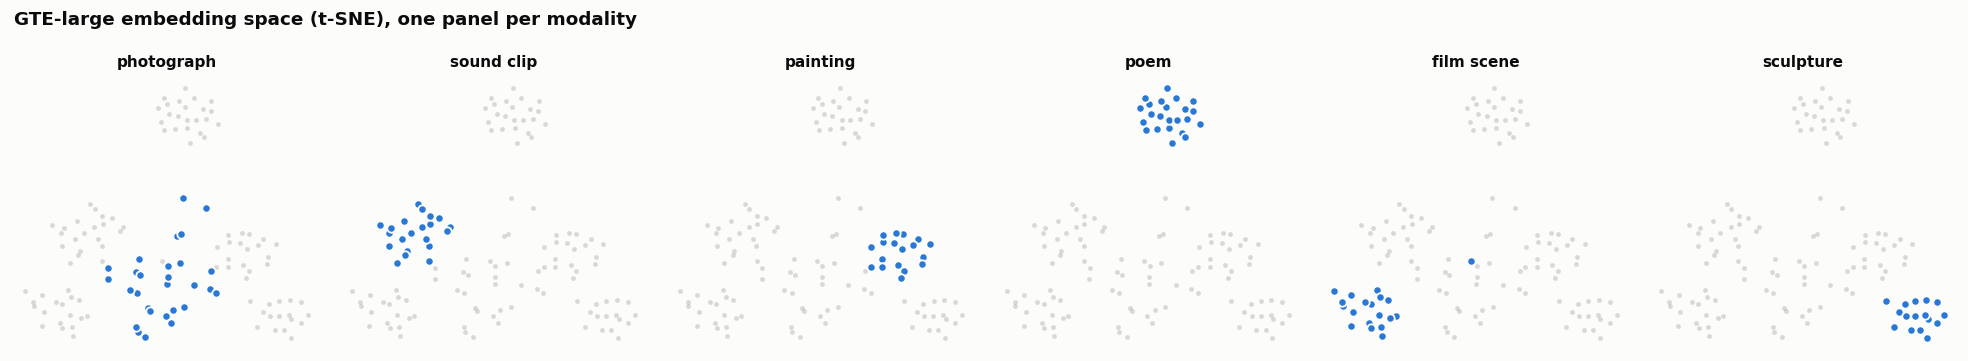

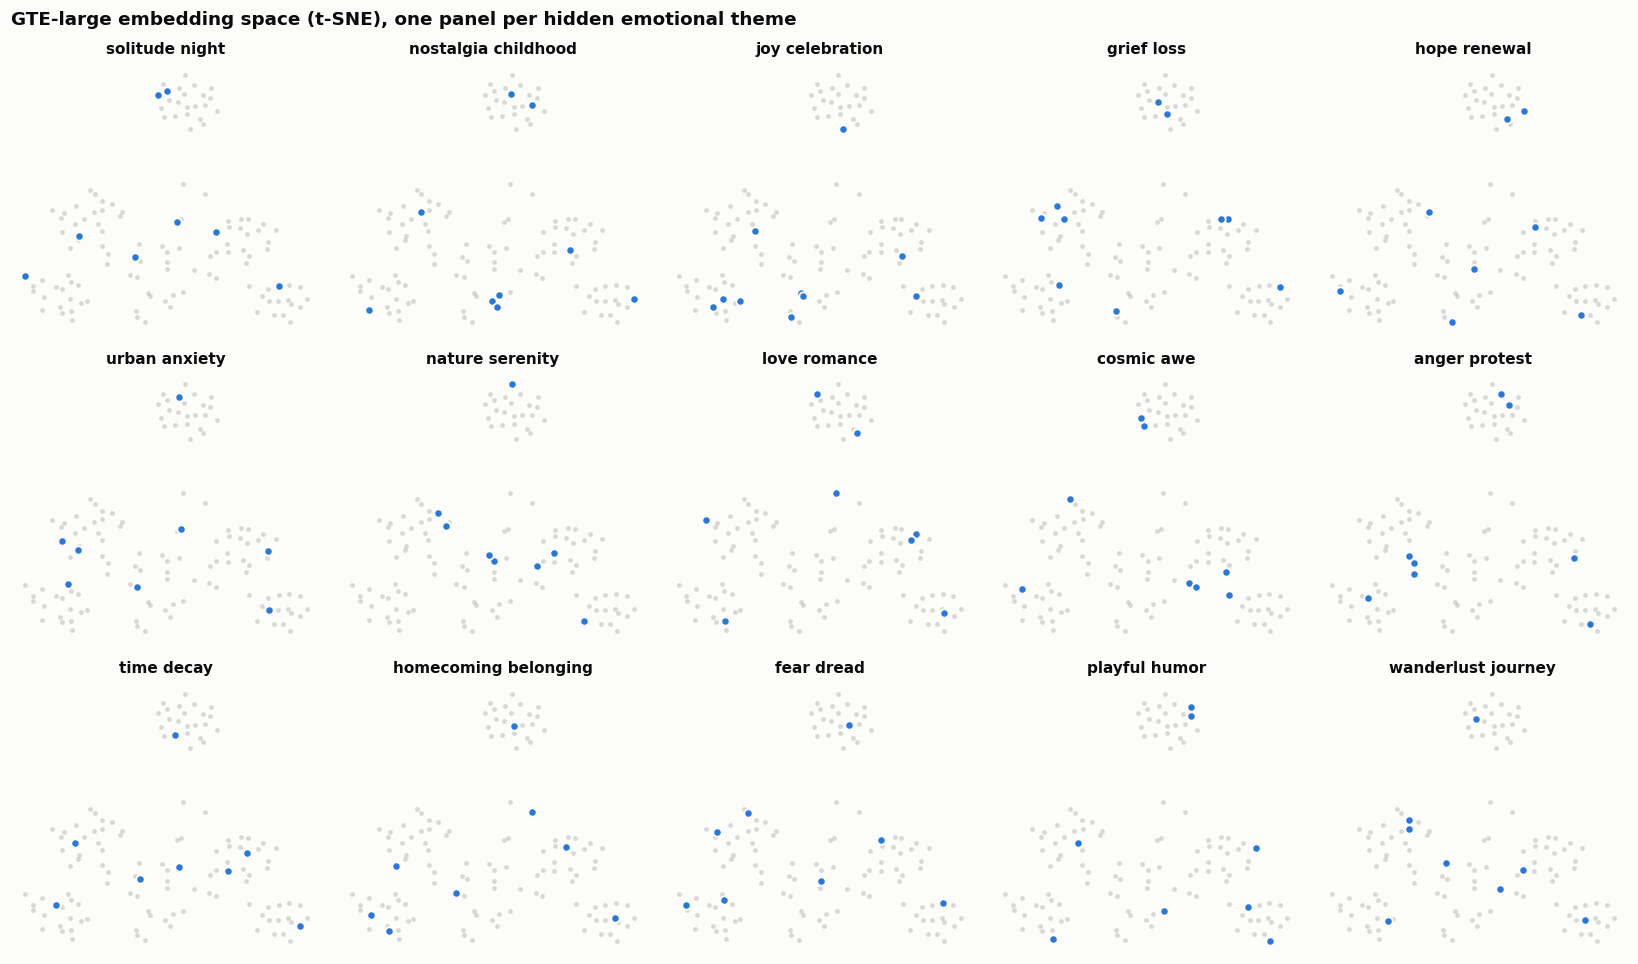

In [14]:
# 2-D maps of the final system's embedding space (t-SNE). Each small panel highlights one group in blue
# and greys out everything else, so a tight blue cluster means the model groups that category together.
vectors = l2_normalize(engines[PRIMARY].item_vectors)
xy = TSNE(n_components=2, perplexity=15, init="pca", random_state=0).fit_transform(vectors)


def highlight_panels(labels, groups, ncols, title):
    nrows = int(np.ceil(len(groups) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 2.8 * nrows + 0.5))
    for ax, group in zip(axes.flat, groups):
        mask = labels == group
        ax.scatter(xy[~mask, 0], xy[~mask, 1], s=10, color=GREY, alpha=0.3, linewidths=0)
        ax.scatter(xy[mask, 0], xy[mask, 1], s=30, color=BLUE, edgecolors=SURFACE, linewidths=1.2)
        ax.set_title(group.replace("_", " "), fontsize=10)
    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    plt.show()


highlight_panels(type_arr, list(dict.fromkeys(type_arr)), 6,
                 f"{PRIMARY} embedding space (t-SNE), one panel per modality")
highlight_panels(theme_arr, list(dict.fromkeys(theme_arr)), 5,
                 f"{PRIMARY} embedding space (t-SNE), one panel per hidden emotional theme")

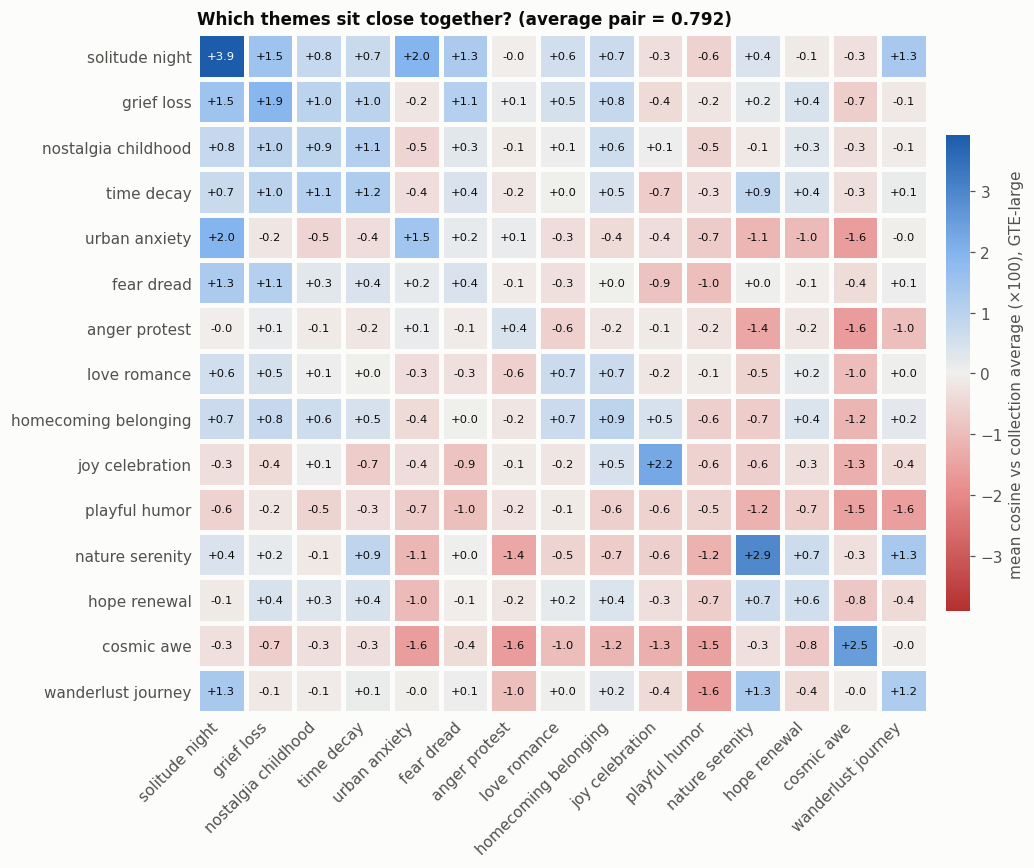

In [15]:
# Which themes does the final system consider close to each other? Mean item-to-item cosine within / between themes.
sims = cosine_similarity_matrix(engines[PRIMARY].item_vectors, engines[PRIMARY].item_vectors)
order = ["solitude_night", "grief_loss", "nostalgia_childhood", "time_decay", "urban_anxiety", "fear_dread",
         "anger_protest", "love_romance", "homecoming_belonging", "joy_celebration", "playful_humor",
         "nature_serenity", "hope_renewal", "cosmic_awe", "wanderlust_journey"]
theme_sim = pd.DataFrame(index=order, columns=order, dtype=float)
for ta in order:
    for tb in order:
        block = sims[np.ix_(theme_arr == ta, theme_arr == tb)]
        theme_sim.loc[ta, tb] = block[~np.eye(len(block), dtype=bool)].mean() if ta == tb else block.mean()

# GTE-large squeezes almost every pair into 0.75-0.85, so raw values hide the structure. Plot each cell
# relative to the average similarity of two different items: blue = closer than average, red = further.
off_diagonal = sims[~np.eye(len(sims), dtype=bool)]
relative = theme_sim - off_diagonal.mean()
limit = np.abs(relative.values).max()

fig, ax = plt.subplots(figsize=(10, 8))
labels = [t.replace("_", " ") for t in order]
mesh = draw_heatmap(ax, relative.values * 100, labels, labels, DIVERGING,
                    plt.Normalize(-limit * 100, limit * 100), fmt="{:+.1f}", fontsize=7.5)
ax.set_xticklabels(labels, rotation=45, ha="right")
cbar = fig.colorbar(mesh, ax=ax, shrink=0.7, pad=0.02,
                    label=f"mean cosine vs collection average (×100), {PRIMARY}")
cbar.outline.set_visible(False)
ax.set_title(f"Which themes sit close together? (average pair = {off_diagonal.mean():.3f})", loc="left")
fig.tight_layout()
plt.show()

### 8.2 How separable are relevant and irrelevant items? (score distributions)

For each model, the cosine scores of **relevant** (grade 2) and **not relevant** items are pooled across all scored queries. The further apart the two distributions, the more reliable the ranking.

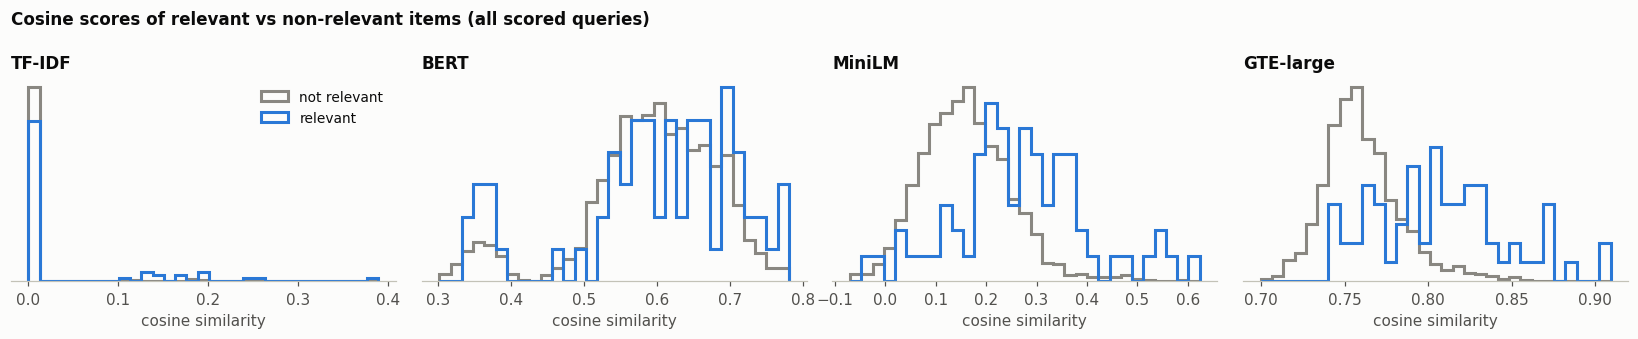

,median (relevant),median (not relevant),gap,range of all scores
model,,,,
TF-IDF,0.000,0.000,0.000,0.00 – 0.39
BERT,0.617,0.601,0.017,0.30 – 0.78
MiniLM,0.265,0.156,0.108,-0.07 – 0.62
GTE-large,0.807,0.757,0.049,0.70 – 0.91


In [16]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.1))
dist_rows = []
for ax, (name, engine) in zip(axes, engines.items()):
    rel_scores, irr_scores = [], []
    for q in scored_queries:
        s = engine.similarities(q["query"])
        grades = np.array([q["relevant"].get(str(i), 0) for i in item_ids])
        rel_scores += list(s[grades == 2])
        irr_scores += list(s[grades == 0])
    rel_scores, irr_scores = np.array(rel_scores), np.array(irr_scores)
    bins = np.linspace(min(rel_scores.min(), irr_scores.min()), max(rel_scores.max(), irr_scores.max()), 32)
    ax.hist(irr_scores, bins, density=True, histtype="step", linewidth=2, color=GREY, label="not relevant")
    ax.hist(rel_scores, bins, density=True, histtype="step", linewidth=2, color=BLUE, label="relevant")
    ax.set_title(name, loc="left")
    ax.set_xlabel("cosine similarity")
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    dist_rows.append({"model": name, "median (relevant)": np.median(rel_scores),
                      "median (not relevant)": np.median(irr_scores),
                      "gap": np.median(rel_scores) - np.median(irr_scores),
                      "range of all scores": f"{min(irr_scores.min(), rel_scores.min()):.2f} – "
                                             f"{max(irr_scores.max(), rel_scores.max()):.2f}"})
axes[0].legend(loc="upper right", fontsize=9)
fig.suptitle("Cosine scores of relevant vs non-relevant items (all scored queries)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()
display(pd.DataFrame(dist_rows).set_index("model").round(3))

### 8.3 Minimal-pair probe: what does the embedding *not* encode?

If embeddings captured meaning perfectly, a paraphrase would score high and a sentence with the **opposite** meaning would score low. Here, pairs of sentences that differ by a single meaning-flipping change are compared directly. A paraphrase pair and an unrelated pair are included as reference points.

In [17]:
pairs = [
    ("paraphrase (should be HIGH)", "coming back to the place where you belong", "returning home after years away"),
    ("unrelated (should be LOW)", "a calm, peaceful morning in nature", "an angry crowd rioting in the city"),
    ("negation", "a night that is lonely", "a night that is not lonely"),
    ("negation", "I am happy", "I am not happy"),
    ("antonym", "rain that makes you want to dance", "rain that makes you want to cry"),
    ("antonym", "a house with all the lights switched on", "a house with all the lights switched off"),
    ("antonym", "coming home", "leaving home"),
    ("role reversal", "the child comforts the old man", "the old man comforts the child"),
]
rows = []
for kind, s1, s2 in pairs:
    row = {"relation": kind, "sentence A": s1, "sentence B": s2}
    for name, engine in engines.items():
        row[name] = cosine_similarity_matrix(engine.encoder.encode([s1]), engine.encoder.encode([s2]))[0, 0]
    rows.append(row)
display(pd.DataFrame(rows).round(3))

,relation,sentence A,sentence B,TF-IDF,BERT,MiniLM,GTE-large
0,paraphrase (should be HIGH),coming back to the place where you belong,returning home after years away,0.000,0.692,0.509,0.875
1,unrelated (should be LOW),"a calm, peaceful morning in nature",an angry crowd rioting in the city,0.000,0.573,0.168,0.709
2,negation,a night that is lonely,a night that is not lonely,1.000,0.965,0.973,0.951
3,negation,I am happy,I am not happy,0.000,0.892,0.720,0.895
4,antonym,rain that makes you want to dance,rain that makes you want to cry,0.603,0.926,0.698,0.902
5,antonym,a house with all the lights switched on,a house with all the lights switched off,1.000,0.972,0.976,0.983
6,antonym,coming home,leaving home,0.428,0.872,0.787,0.901
7,role reversal,the child comforts the old man,the old man comforts the child,1.000,0.973,0.967,0.983


**Negation in retrieval.** The full Q7 query (*"a night that is not lonely at all, full of people and celebration"*) did well in Section 6. Is that because the model understood "not lonely", or because the words "full of people and celebration" carried the meaning on their own? To find out, the query is stripped down to only its negated part and compared with its non-negated twin. The judgements use Q7's labels.

In [18]:
q7 = next(q for q in queries if q["qid"] == "Q7")
for name in ["GTE-large", "MiniLM"]:
    columns, tops = {}, []
    for text in ["a night that is lonely", "a night that is not lonely"]:
        ids, scores = engines[name].ranking(text)
        tops.append(set(ids[:TOP_K]))
        columns[(text, "retrieved item")] = [f"[{i}] {items.loc[i, 'title']}" for i in ids[:TOP_K]]
        columns[(text, "cos")] = scores[:TOP_K].round(3)
        columns[(text, "Q7 judgement")] = [judge(q7, i) for i in ids[:TOP_K]]
    display(Markdown(f"**{name}**: {len(tops[0] & tops[1])} of the 5 items are shared by both queries"))
    display(pd.DataFrame(columns, index=pd.RangeIndex(1, TOP_K + 1, name="rank")))

**GTE-large**: 3 of the 5 items are shared by both queries

a night that is lonely                     a night that is not lonely                    
             retrieved item    cos Q7 judgement             retrieved item    cos Q7 judgement
rank                                                                                          
1         [18] Night Market  0.846   ✓ relevant          [18] Night Market  0.849   ✓ relevant
2            [97] Footsteps  0.841            ✗             [121] Blackout  0.820   ✓ relevant
3           [60] Voice Note  0.834            ✗          [21] Street Party  0.816   ✓ relevant
4          [8] Ghost Signal  0.832      ✗ DECOY             [97] Footsteps  0.813            ✗
5            [121] Blackout  0.831   ✓ relevant       [17] The Eid Express  0.809   ✓ relevant

**MiniLM**: 4 of the 5 items are shared by both queries

a night that is lonely                     a night that is not lonely                    
                 retrieved item    cos Q7 judgement             retrieved item    cos Q7 judgement
rank                                                                                              
1            [48] Neon Insomnia  0.419      ✗ DECOY          [18] Night Market  0.409   ✓ relevant
2             [18] Night Market  0.411   ✓ relevant         [48] Neon Insomnia  0.404      ✗ DECOY
3        [116] Caravan at Night  0.398    ~ partial     [116] Caravan at Night  0.384    ~ partial
4     [117] Sleeper Compartment  0.391    ~ partial        [63] Six Time Zones  0.379            ✗
5           [63] Six Time Zones  0.389            ✗              [4] Night Bus  0.373      ✗ DECOY

### 8.4 Modality constraints (Q6: *"a sound clip that captures grief"*)

The modality is part of each item's text (`"Sound clip: ..."`), so the embedding *can* see it. Does the model balance the modality ("sound clip") against the emotion ("grief")?

In [19]:
q6 = next(q for q in queries if q["qid"] == "Q6")
modality_rows = []
for name, engine in engines.items():
    ids, _ = engine.ranking(q6["query"])
    top = ids[:TOP_K]
    modality_rows.append({
        "model": name,
        "sound clips in top 5": int((items.loc[top, "type"] == "sound clip").sum()),
        "grief sound clips (grade 2) in top 5": sum(q6["relevant"].get(str(i), 0) == 2 for i in top),
        "best-ranked grief item that is NOT a sound clip": next(
            f"rank {r}: {items.loc[i, 'title']} ({items.loc[i, 'type']})"
            for r, i in enumerate(ids, 1) if q6["relevant"].get(str(i), 0) == 1),
        "non-grief sound clips in top 5": ", ".join(items.loc[i, "title"] for i in top if str(i) not in q6["relevant"]),
    })
display(pd.DataFrame(modality_rows).set_index("model"))

,sound clips in top 5,grief sound clips (grade 2) in top 5,best-ranked grief item that is NOT a sound clip,non-grief sound clips in top 5
model,,,,
TF-IDF,5,0,rank 44: The Empty Place Setting (painting),"Static Call, Plasma Waves, Open Road, Harbour at Dusk, March"
BERT,4,1,rank 17: Hollow Figure (sculpture),"Goat Choir, Wedding Drums, Noise Tower, Static Call"
MiniLM,5,3,rank 27: Ashes at Sea (film scene),"Voice Note, Wedding Drums"
GTE-large,5,3,rank 7: Ashes at Sea (film scene),"Ice-Cream Van, Far Away, Goat Choir"


### 8.5 Cross-lingual query (Q13 in English vs Q14 in Arabic)

Q13 and Q14 carry the same meaning, *nostalgia for the days of childhood*, in English and in Arabic. The models used here were trained on English text, so the Arabic query tests what happens outside the model's language. The tokenizer output shows why.

In [20]:
q13, q14 = (next(q for q in queries if q["qid"] == x) for x in ("Q13", "Q14"))
print("Arabic query:", q14["query"])
for name in ["GTE-large", "MiniLM"]:
    tokens = engines[name].encoder.tokenizer.tokenize(q14["query"])
    print(f"{name:>10} tokens ({len(tokens)}): {tokens}")
print("    TF-IDF non-zero dims:", int((engines['TF-IDF'].encoder.encode([q14['query']]) != 0).sum()),
      "(no Arabic word exists in the vocabulary, so the query vector is all zeros)\n")

display(metrics[metrics.qid.isin(["Q13", "Q14"])].pivot(index="model", columns="qid", values=["nDCG@5", "P@5"])
        .loc[MODELS].round(2))
for name in ["GTE-large", "MiniLM"]:
    print(f"\n{name}: top 5 for the Arabic query")
    top = engines[name].search(q14["query"])
    top["judgement"] = [judge(q14, i) for i in top.index]
    display(top)

Arabic query: الحنين إلى أيام الطفولة
 GTE-large tokens (20): ['ا', '##ل', '##ح', '##ن', '##ي', '##ن', 'ا', '##ل', '##ى', 'ا', '##ي', '##ا', '##م', 'ا', '##ل', '##ط', '##ف', '##و', '##ل', '##ة']
    MiniLM tokens (20): ['ا', '##ل', '##ح', '##ن', '##ي', '##ن', 'ا', '##ل', '##ى', 'ا', '##ي', '##ا', '##م', 'ا', '##ل', '##ط', '##ف', '##و', '##ل', '##ة']
    TF-IDF non-zero dims: 0 (no Arabic word exists in the vocabulary, so the query vector is all zeros)



nDCG@5       P@5     
qid          Q13  Q14  Q13  Q14
model                          
TF-IDF      0.34  0.0  0.2  0.0
BERT        0.60  0.0  0.6  0.0
MiniLM      0.55  0.0  0.4  0.0
GTE-large   1.00  0.0  1.0  0.0


GTE-large: top 5 for the Arabic query


,rank,type,title,cosine,judgement
id,,,,,
56,1,photograph,Desert Dawn,0.791,✗
92,2,sound clip,Mother Tongue,0.787,✗
17,3,film scene,The Eid Express,0.782,✗
116,4,painting,Caravan at Night,0.781,✗
24,5,film scene,Goal!,0.780,✗



MiniLM: top 5 for the Arabic query


,rank,type,title,cosine,judgement
id,,,,,
56,1,photograph,Desert Dawn,0.245,✗
116,2,painting,Caravan at Night,0.209,✗
5,3,photograph,"Laundromat, 2 AM",0.205,✗
3,4,painting,Gate 31,0.194,✗
115,5,poem,Map,0.192,✗


### 8.6 Can rephrasing the query fix the failures?

If a failure comes from *how the query is worded* (negation, metaphor) rather than from missing knowledge, then restating the same intent literally should fix it. Each rewrite below states the intended meaning plainly. They were written once from the `intent` field and not tuned against the results. In a real system this rewriting step could be done automatically by an LLM before embedding.

In [21]:
rewrites = {
    "Q7": "a crowded, festive night where people celebrate together",
    "Q8": "grief, emptiness and sadness after losing someone",
    "Q9": "people joyfully dancing in the rain",
    "Q14": "nostalgia for the days of childhood",  # machine translation of the Arabic query
}
rows = []
for qid, rewrite in rewrites.items():
    q = next(x for x in queries if x["qid"] == qid)
    for name in ["GTE-large", "MiniLM"]:
        before = evaluate_ranking(*engines[name].ranking(q["query"]), q)
        after = evaluate_ranking(*engines[name].ranking(rewrite), q)
        rows.append({"qid": qid, "model": name, "rewritten query": rewrite,
                     "nDCG@5 before": before["nDCG@5"], "nDCG@5 after": after["nDCG@5"],
                     "decoys before": before["Decoys@5"], "decoys after": after["Decoys@5"]})
display(pd.DataFrame(rows).set_index(["qid", "model"]).round(2))

rewritten query  nDCG@5 before  nDCG@5 after  decoys before  decoys after
qid model                                                                                                                        
Q7  GTE-large  a crowded, festive night where people celebrate together           0.91          0.87              0             0
    MiniLM     a crowded, festive night where people celebrate together           0.56          0.69              0             0
Q8  GTE-large         grief, emptiness and sadness after losing someone           0.48          0.80              2             0
    MiniLM            grief, emptiness and sadness after losing someone           0.48          0.73              1             0
Q9  GTE-large                       people joyfully dancing in the rain           0.85          0.86              2             1
    MiniLM                          people joyfully dancing in the rain           0.86          0.87              1             1
Q14 GTE-large                       nostalgia for the days of childhood           0.00          1.00              0             0
    MiniLM                          nostalgia for the days of childhood           0.00          0.55              0             0

### 8.7 The ambiguous one-word query (Q11: *"blue"*)

In [22]:
for name in ["GTE-large", "MiniLM", "TF-IDF"]:
    print(name)
    display(engines[name].search("blue"))

GTE-large


,rank,type,title,cosine
id,,,,
48,1,photograph,Neon Insomnia,0.799
99,2,painting,The Visitor,0.798
3,3,painting,Gate 31,0.798
68,4,painting,Nebula Study,0.796
35,5,painting,First Light Over the Ward,0.792


MiniLM


,rank,type,title,cosine
id,,,,
99,1,painting,The Visitor,0.317
125,2,painting,Grey Weeks,0.288
20,3,painting,Fireworks Over the Harbour,0.284
48,4,photograph,Neon Insomnia,0.280
42,5,painting,Deadline,0.273


TF-IDF


,rank,type,title,cosine
id,,,,
69,1,film scene,Earthrise,0.242
48,2,photograph,Neon Insomnia,0.236
3,3,painting,Gate 31,0.201
1,4,photograph,"Platform 4, 3:12 AM",0.000
2,5,sound clip,Last Announcement,0.000


## 9. Discussion

### 9.1 Manual assessment of the final system (GTE-large), query by query

| Query | Top-5 verdict | What happened |
|---|---|---|
| **Q1** loneliness of an empty train station at 3 AM | 2 ✓, 2 ~, 1 decoy | *Platform 4, 3:12 AM* is ranked 1st and *Last Announcement* 5th. *Sleeper Compartment* (a warm, talkative night train) is a decoy pulled in by "train" + "night". MiniLM does much worse: its #1 is *Rush Hour, Line 2*, a packed train, the opposite of empty. |
| **Q2** bittersweet childhood summer | 2 ✓ then 3 ✗ | *Polaroid, August 1998* and *Last Day of the Holidays* are perfect. Ranks 3–5 (*Ashes at Sea*, *Time-Lapse House*, *The Long Way Home*) match "bittersweet" but not "childhood summer". |
| **Q3** feeling tiny under the vastness of the universe | 5 ✓ | Excellent, with no shared keywords needed ("vastness" ↔ "billions of stars", "a speck of dust"). |
| **Q4** burning rage against injustice | 5 ✓ | Excellent: protest, eviction, a melted scale of justice. TF-IDF's #1 was *Lamp in the Window*, because its lamp is "left burning". |
| **Q5** calm, peaceful morning in nature | 4 ✓, 1 ~ | Good. MiniLM's #1 was the decoy *Morning After*, a storm-damage poem that shares the word "morning". |
| **Q6** a sound clip that captures grief | 3 ✓, 2 ✗ | The three grief sound clips fill ranks 1–3. Ranks 4–5 are *Ice-Cream Van* and *Goat Choir*: sound clips, but not grief. |
| **Q7** a night that is not lonely, full of people and celebration | 4 ✓, 1 ~ | Looks like a success, but Section 8.3 shows it comes from "full of people and celebration", not from understanding "not lonely". |
| **Q8** a heart like a house with all the lights switched off | 1 ✓, 2 decoys | Only *The House After* is found, and it literally mentions a house and lights. *Blackout* (a joyful rooftop party in a power cut) and *Lamp in the Window* are literal decoys. *Grey Weeks* (depression) is ranked 24th. |
| **Q9** rain that makes you want to dance | 2 ✓, 1 ~, 2 decoys | Both joyful-rain items are ranks 1–2. After that "rain" takes over: a calm tin roof and a funeral in the rain. |
| **Q10** coming back to the place where you belong | 3 ✓, 1 ~ | *The Long Way Home* is ranked 1st with zero shared words. *Arrivals, Central Station* (a soldier's homecoming told only through action) is ranked 45th. |
| **Q11** "blue" | – | GTE-large picks the colour sense (lit blue, dark blues, blue hour, teal nebula). MiniLM mixes in the mood sense (*Grey Weeks* at #2). |
| **Q12** something funny and absurd | 2 ✓, 1 ~, 2 decoys | *The Very Serious Duck* is ranked 1st, but *The Old Cartoon* and *Traffic Jam* (laughter in sad or panicked contexts) outrank most jokes. *Dog in Sunglasses* is ranked 65th. |
| **Q13** nostalgia for the days of childhood | 5 ✓ | Excellent. |
| **Q14** the same query in Arabic | 0 ✓ | Complete failure. It returns *Desert Dawn*, *Mother Tongue*, *The Eid Express*, *Caravan at Night* (see 9.3). |

### 9.2 What types of queries produced good or poor results?

**Good (GTE-large nDCG@5 ≥ 0.83):** awe (Q3), anger at injustice (Q4), English nostalgia (Q13), grief sound clip (Q6), the literal nature query (Q5), joyful rain (Q9) and homecoming (Q10). The negation query Q7 also scores 0.91, but for the wrong reason (Section 9.4). What these share is that the intended meaning is **stated with concepts that the item descriptions depict**, even if in different words. The embedding bridges the vocabulary gap: *universe* ↔ *galaxies, Milky Way*; *injustice* ↔ *eviction, twelve hours for bread*; *belong* ↔ *his mother recognises his walk*. TF-IDF cannot make these links, which is why it scores 0.00–0.21 on Q3, Q4, Q6, Q7 and Q10.

**Middling (0.65–0.68):** queries that pair an **emotion with a concrete setting** (Q1 *lonely + train station*, Q2 *bittersweet + childhood summer*). The concrete nouns are strong signals, so items with the right setting and the wrong mood compete with the right ones.

**Poor:** queries whose meaning has to be **inferred rather than read off the words**:
- metaphor (Q8, 0.48 for TF-IDF, MiniLM and GTE-large alike: all three find only the one item that shares the words "house" and "lights");
- humour (Q12, 0.52): the joke lives in the situation (a sock with lawyers), and no description says "funny";
- the Arabic query (Q14, 0.00);
- the one-word query (Q11), where the model silently picks one sense.

**Model capacity matters most on the harder queries.** The gap between MiniLM and GTE-large is small on easy, keyword-rich queries (Q9: 0.86 vs 0.85; Q6: 0.80 vs 0.89) but large on paraphrase and setting-heavy queries (Q10: 0.37 vs 0.83; Q1: 0.19 vs 0.65; Q5: 0.36 vs 0.86). The small model leans more on surface overlap: "morning" → *Morning After*, "train" → *Rush Hour*.

### 9.3 Did the system retrieve items related to the topic but not the intended meaning?

Yes, and the decoy count measures it. Across the 13 scored queries, **decoys filled 7 top-5 slots for GTE-large, 9 for MiniLM and 10 for TF-IDF**, against about 1.3 expected by chance. The decoys follow a clear pattern: they share a **salient concrete word or setting** with the query while carrying a different or even opposite feeling.

* *train / station* → a packed rush-hour train, a warm sleeper compartment, a family reunion on a platform (Q1)
* *house + lights* → a joyful blackout party, a lamp left burning for a traveller (Q8)
* *rain* → calm rain on a tin roof, rain at a funeral (Q9)
* *laughing* → a driver laughing in panic, a man who laughs and then cries at an old cartoon (Q12)
* *home* → MiniLM retrieves *Departure*, a woman *leaving* her hometown (Q10), the exact opposite

Raw BERT has the fewest decoys (4), but not because it understands intent: its rankings are close to topic-blind (P@5 0.32). It rarely retrieves *any* topically related item, decoy or not.

The **Arabic query (Q14)** is a special case of "related but not meant". The tokenizer shreds it into 20 single letters, so the model cannot read it. Yet the results are not random. All three transformer models rank *Caravan at Night* in their top 4, MiniLM and GTE-large both put *Desert Dawn* first, and GTE-large adds *Mother Tongue* (a native dialect) and *The Eid Express*. The models have learned an association between Arabic script and desert or Middle-Eastern imagery, and they retrieve by that **cultural association** instead of by meaning. This is a small, concrete example of how embedding bias surfaces in retrieval.

### 9.4 Which semantic relationships were captured well, and which poorly?

**Captured well**
* **Conceptual similarity / synonymy across different words.** Examples are *vastness of the universe* ↔ *thousands of galaxies* and *grief* ↔ *a saved voicemail from a father who has since died*. This is the core strength of contrastively trained sentence embeddings, and it is absent from TF-IDF.
* **Paraphrase.** *"coming back to the place where you belong"* vs *"returning home after years away"* scores 0.875 with GTE-large, well above its unrelated-pair level (0.709). With TF-IDF the same pair scores exactly 0.
* **Broad emotional families.** In Section 8.1, the melancholic themes (loneliness at night, grief, nostalgia, time/decay) are all closer to each other than average, while joy and cosmic awe are mostly further from them than average.
* **Explicit modality words.** "sound clip" reliably retrieves sound clips (5/5 for GTE-large, MiniLM and TF-IDF). This works because the modality is literally written in the item text.

**Captured poorly**
* **Negation.** *"a night that is lonely"* vs *"a night that is not lonely"* scores 0.95–0.97 for every transformer, *higher* than the paraphrase pair. Retrieving with either query gives nearly the same top 5 (3 of 5 items shared for GTE-large, 4 of 5 for MiniLM).
* **Antonyms and polarity.** *lights switched on / off* scores 0.98 and *coming home / leaving home* 0.90 with GTE-large. Opposites share their topic, so they sit close together.
* **Word order and roles.** *"the child comforts the old man"* vs *"the old man comforts the child"* scores 0.97–0.98. Mean pooling is close to a bag of contextual words.
* **Figurative language, humour and implied meaning.** Examples are *Grey Weeks* at rank 24 for the metaphor query, *Arrivals* at rank 45 for homecoming and *Dog in Sunglasses* at rank 65 for "funny". These need inference beyond "which concepts are mentioned".
* **Balancing two constraints.** In Q6 the modality words outweigh the emotion: joyful *Wedding Drums* and nostalgic *Ice-Cream Van* outrank grief items in other modalities (the best-ranked one is at rank 7 for GTE-large and 27 for MiniLM).
* **Form versus feeling.** The embedding space is organised far more by **what an item is and how it is written** than by **how it feels**. An item's nearest neighbour shares its modality 92% of the time with GTE-large (chance: 17%), but its emotional theme only 17% of the time (chance: 6%). With the modality prefix and title removed, modality agreement is still 50%: poems cluster through their line-break style, sound clips through words like "recording". The modality t-SNE panels show tight clusters, while the theme panels are scattered. Themes defined by a shared *subject* (night scenes, nature, space) cluster clearly; themes defined by *tone* (humour, fear, hope, anger) cluster weakly or not at all. Humour items are even slightly *less* similar to each other than two random items are.

### 9.5 Limitations and failure cases of embedding-based retrieval for this application

1. **Similarity is not relevance.** Cosine similarity measures shared topic and concepts. It is blind to polarity, negation and roles, which are exactly what emotional queries often hinge on ("not lonely", "leaving vs coming home").
2. **Figurative, ironic and humorous meaning is out of reach.** These require reasoning about what a text *implies*, which a single fixed vector computed without the query cannot do.
3. **Surface features dominate.** Shared salient words (train, night, morning, burning, rain, laughing) and writing format decide much of the ranking, and bigger models only partly fix this.
4. **Scores are uncalibrated.** GTE-large puts almost every pair between 0.70 and 0.91: an unrelated pair scores 0.709, and the unreadable Arabic query's top hit scores 0.791, close to the 0.807 of a correct English match. MiniLM uses −0.07 to 0.62, and raw BERT is anisotropic: every text looks similar to every other (0.30–0.78, with a relevant/irrelevant gap of only 0.017). A fixed "good match" threshold is therefore impossible. The system **always returns five items**, even when it has understood nothing.
5. **Language coverage.** English-only vocabularies cannot represent Arabic (Q14 nDCG 0.00 for every model), and the failure is silent: confident-looking results with a cultural bias instead of an error.
6. **Text as a stand-in for the artefact.** The system retrieves *descriptions* of paintings and sounds, not the works themselves. Quality depends on how the descriptions are written. A real collection would need multimodal embeddings (e.g. CLIP for images, CLAP for audio), which bring their own gaps.
7. **Evaluation caveats.** The collection (125 items) and query set (13 scored queries) are small. Items, queries and relevance labels were written by the same person, and relevance for emotional queries is subjective. The collection was also deliberately seeded with decoys, so absolute scores are likely pessimistic compared with a natural collection. The *relative* comparisons between models and query types are the robust findings.
8. **Cost.** GTE-large (335M parameters) took roughly 20–25 s to index 125 items on CPU versus about 1 s for MiniLM. Irrelevant at this scale, but for a real museum catalogue it would need batching, GPU inference and an approximate-nearest-neighbour index.

### 9.6 What would help, supported by the experiments above

* **Rewrite the query into literal language before embedding** (e.g. with an LLM). Stating the metaphor's meaning literally raised Q8 from 0.48 to 0.80 (GTE-large) and removed every decoy. Translating Q14 raised it from 0.00 to 1.00. Rephrasing Q9 changed little, which suggests its remaining errors come from the collection, not the wording.
* **Handle hard constraints outside the embedding.** Filter on metadata such as modality, and let the embedding rank only within the allowed set.
* **Re-rank the top ~20 with a cross-encoder**, which reads query and item *together* and can therefore attend to "not", word order and roles, which a single pooled vector loses.
* **Use multilingual embedding models** for non-English visitors, and **multimodal models** to embed the artworks themselves.

### 9.7 Conclusion

Embeddings turn "find something that *feels* like this" into a geometric nearest-neighbour search, and it works remarkably well when the feeling is expressed through concepts that the items depict. GTE-large reaches nDCG@5 = 0.74 against 0.18 for TF-IDF and 0.06 for random ranking, and retrieves perfectly on awe, injustice and nostalgia without any shared keywords. The experiments also show the limits of this geometry. It encodes *what a text is about* much more than *what it asserts*: negation, opposites, roles, metaphor and humour barely move a vector. It organises works more by form than by feeling. It cannot tell when it has not understood the query. Embedding-based retrieval is a strong first-stage recall mechanism for creative search, but understanding the *intended* meaning needs extra machinery on top: query rewriting, constraint filters and re-ranking.

## 10. Try your own query

In [23]:
def search(query, model=PRIMARY, k=TOP_K):
    """Top-k items for any natural-language query."""
    return engines[model].search(query, k)


search("a small act of kindness after a disaster")

,rank,type,title,cosine
id,,,,
39,1,photograph,Rebuilding,0.863
34,2,poem,Morning After,0.844
121,3,photograph,Blackout,0.808
124,4,film scene,Downpour Tango,0.808
57,5,poem,Under One Umbrella,0.808
